# Predicting the Nutrition Score of Packaged Foods

## Mission
My mission is to promote healthier lifestyles in Nigeria by helping young urban Nigerians make informed food choices and rely less on ultra-processed packaged food.

## Use case
Packaged foods sold in Nigeria usually print a nutrition table, but not an overall health rating like the Nutri-Score used in Europe. Reading a table of grams per 100 g and judging how healthy a product is takes knowledge most shoppers do not have.

This model predicts the **Nutri-Score nutrition points** of a packaged food (from about -15 to 40, lower is healthier) using the numbers already printed on the label, the food group and signs of ultra-processing (number of additives, palm oil ingredients).

**Who uses the prediction:** young urban Nigerians (18 to 35) in supermarkets and markets, through a mobile app. They type in the label values and get one score, so they can compare products and pick the healthier option. Nutrition educators and health campaigns can use it the same way to compare local products.

## Mission canvas

| | |
|---|---|
| **Problem** | Young urban Nigerians eat more packaged and convenience food, and labels are hard to interpret, so unhealthy ultra-processed products are hard to spot. |
| **Who it serves** | Young urban Nigerians choosing food, plus nutrition educators and health campaigns. |
| **Target y** | Nutri-Score nutrition points per 100 g (`nutrition_score`, -15 to 40, lower is healthier). |
| **Features X** | Food group, number of additives, palm oil ingredients, energy (kJ), fat, saturated fat, carbohydrates, sugars, fibre, protein and salt per 100 g. |
| **Data source** | Open Food Facts (real, crowdsourced product labels), Kaggle upload `openfoodfacts/world-food-facts`. |
| **Success metric** | Test RMSE clearly below a baseline that always predicts the average score (about 9 points). |
| **Risks and ethics** | Very few Nigerian products in the data (mostly European/US products). Crowdsourced labels contain errors. A wrong low score could make a junk food look healthy, so the app is for information only. No personal data is used. |
| **Mission sentence** | Predict the nutrition score of a packaged food for young urban Nigerians, using its label values, food group and additives, so that they can spot unhealthy ultra-processed products and choose healthier alternatives. |

## Dataset
- Source: https://www.kaggle.com/datasets/openfoodfacts/world-food-facts
- Raw file: 356,027 products and 163 columns (`en.openfoodfacts.org.products.tsv`, about 1 GB).
- The raw file is too big for GitHub, so section 1 cleans it once and saves a small CSV (`summative/API/food_nutrition_clean.csv`). The rest of the notebook only needs that CSV, and the API uses the same file for retraining.

In [1]:
import os
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

In [2]:
# Paths. Running inside the repo, the cleaned data and the saved model live in
# summative/API. On Google Colab, upload food_nutrition_clean.csv to the session
# (or let it download from GitHub) and outputs are saved in the working folder.
RAW_PATH = "data/en.openfoodfacts.org.products.tsv"
API_DIR = "../API" if os.path.isdir("../API") else "."
CLEAN_PATH = os.path.join(API_DIR, "food_nutrition_clean.csv")
SAMPLE_PATH = os.path.join(API_DIR, "retrain_sample.csv")
MODEL_PATH = os.path.join(API_DIR, "best_model.pkl")
GITHUB_CSV = ("https://raw.githubusercontent.com/Bangnyfe/Regression-Analysis-Mobile-Application/"
              "main/summative/API/food_nutrition_clean.csv")
print("API folder:", os.path.abspath(API_DIR))

API folder: C:\Users\ahmad\Documents\Flutter Projects\Regression-Analysis-Mobile-Application\summative\API


## 1. Cleaning the raw data

This step only runs when the raw Kaggle file is in `linear_regression/data/`. Otherwise it is skipped and the saved CSV is used.

What the cleaning does:
1. Loads only the columns that could matter. Most of the 163 columns are almost empty (for example vitamins and minerals are missing for over 90% of products), or are URLs, timestamps and creator names that say nothing about nutrition.
2. Keeps rows that have the target and every nutrient, the additives count and a known food group (`pnns_groups_1`).
3. Merges food group labels that are spelled two ways (`sugary-snacks` and `Sugary snacks`).
4. Removes rows that are physically impossible, such as more than 100 g of a nutrient per 100 g, more saturated fat than total fat, more sugar than carbohydrate, or energy above 3,800 kJ (pure fat is about 3,700 kJ).
5. Renames columns to simple names that also work as API field names.
6. Holds back 300 random products as `retrain_sample.csv`. They are never used in this notebook and play the role of "new data" for the `/retrain` endpoint.

In [3]:
RAW_COLUMNS = {
    "product_name": "product_name",
    "countries_en": "countries",
    "pnns_groups_1": "food_group",
    "pnns_groups_2": "food_subgroup",
    "additives_n": "additives_n",
    "ingredients_from_palm_oil_n": "palm_oil_ingredients_n",
    "ingredients_that_may_be_from_palm_oil_n": "maybe_palm_oil_ingredients_n",
    "energy_100g": "energy_kj",
    "fat_100g": "fat_g",
    "saturated-fat_100g": "saturated_fat_g",
    "carbohydrates_100g": "carbohydrates_g",
    "sugars_100g": "sugars_g",
    "fiber_100g": "fiber_g",
    "proteins_100g": "proteins_g",
    "salt_100g": "salt_g",
    "nutrition-score-fr_100g": "nutrition_score",
}

if os.path.exists(RAW_PATH):
    raw = pd.read_csv(RAW_PATH, sep="\t", usecols=list(RAW_COLUMNS), low_memory=False)
    print("Raw rows:", len(raw))
    df_clean = raw.rename(columns=RAW_COLUMNS)

    required = ["food_group", "additives_n", "palm_oil_ingredients_n", "maybe_palm_oil_ingredients_n",
                "energy_kj", "fat_g", "saturated_fat_g", "carbohydrates_g", "sugars_g",
                "fiber_g", "proteins_g", "salt_g", "nutrition_score"]
    df_clean = df_clean.dropna(subset=required)

    df_clean["food_group"] = df_clean["food_group"].str.replace("-", " ").str.capitalize()
    df_clean["food_subgroup"] = df_clean["food_subgroup"].str.replace("-", " ").str.capitalize()
    df_clean = df_clean[df_clean["food_group"] != "Unknown"]
    print("Rows with target, nutrients and a known food group:", len(df_clean))

    grams = ["fat_g", "saturated_fat_g", "carbohydrates_g", "sugars_g", "fiber_g", "proteins_g", "salt_g"]
    impossible = (
        (df_clean[grams] < 0).any(axis=1)
        | (df_clean[grams] > 100).any(axis=1)
        | (df_clean["saturated_fat_g"] > df_clean["fat_g"] + 0.01)
        | (df_clean["sugars_g"] > df_clean["carbohydrates_g"] + 0.01)
        | (df_clean["energy_kj"] > 3800)
        | (df_clean[["fat_g", "carbohydrates_g", "proteins_g", "fiber_g"]].sum(axis=1) > 105)
    )
    print("Impossible rows removed:", impossible.sum())
    df_clean = df_clean[~impossible]

    int_cols = ["additives_n", "palm_oil_ingredients_n", "maybe_palm_oil_ingredients_n", "nutrition_score"]
    df_clean[int_cols] = df_clean[int_cols].astype(int)
    df_clean = df_clean[list(RAW_COLUMNS.values())].reset_index(drop=True)

    retrain_sample = df_clean.sample(300, random_state=RANDOM_STATE)
    df_clean = df_clean.drop(retrain_sample.index).reset_index(drop=True)

    df_clean.to_csv(CLEAN_PATH, index=False)
    retrain_sample.to_csv(SAMPLE_PATH, index=False)
    print(f"Saved {len(df_clean)} rows to {CLEAN_PATH} and {len(retrain_sample)} rows to {SAMPLE_PATH}")
else:
    print("Raw file not found, skipping cleaning and using the saved CSV.")

Raw rows: 356027
Rows with target, nutrients and a known food group: 36065


Impossible rows removed: 257


Saved 35508 rows to ../API\food_nutrition_clean.csv and 300 rows to ../API\retrain_sample.csv


## 2. Loading the cleaned data

In [4]:
for source in [CLEAN_PATH, "food_nutrition_clean.csv", GITHUB_CSV]:
    try:
        df = pd.read_csv(source)
        print("Loaded from:", source)
        break
    except (FileNotFoundError, OSError, ValueError):
        continue
else:
    raise FileNotFoundError("Could not find food_nutrition_clean.csv. Upload it to the notebook folder.")

print(df.shape)
df.head()

Loaded from: ../API\food_nutrition_clean.csv
(35508, 16)


,product_name,countries,food_group,food_subgroup,additives_n,palm_oil_ingredients_n,maybe_palm_oil_ingredients_n,energy_kj,fat_g,saturated_fat_g,carbohydrates_g,sugars_g,fiber_g,proteins_g,salt_g,nutrition_score
0,Salade Cesar,Canada,Fruits and vegetables,Vegetables,0,0,0,1210.0,12.00,7.00,23.00,0.000,2.000,22.00,2.160000,6
1,Chaussons tressés aux pommes,Canada,Sugary snacks,Biscuits and cakes,5,0,0,1090.0,10.70,2.00,38.70,24.700,2.000,3.33,0.647000,9
2,Root Beer,France,Beverages,Sweetened beverages,3,0,0,215.0,0.00,0.00,14.20,13.600,0.000,0.00,0.061600,18
3,Quiche Lorraine,Canada,Composite foods,Pizza pies and quiche,3,0,0,478.0,6.79,2.86,7.86,0.714,0.357,5.36,0.499000,2
4,Luxury Christmas Pudding,United Kingdom,Sugary snacks,Biscuits and cakes,4,0,0,1284.0,7.00,3.60,54.20,44.000,4.700,3.90,0.199898,10


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35508 entries, 0 to 35507
Data columns (total 16 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   product_name                  35482 non-null  str    
 1   countries                     35501 non-null  str    
 2   food_group                    35508 non-null  str    
 3   food_subgroup                 35508 non-null  str    
 4   additives_n                   35508 non-null  int64  
 5   palm_oil_ingredients_n        35508 non-null  int64  
 6   maybe_palm_oil_ingredients_n  35508 non-null  int64  
 7   energy_kj                     35508 non-null  float64
 8   fat_g                         35508 non-null  float64
 9   saturated_fat_g               35508 non-null  float64
 10  carbohydrates_g               35508 non-null  float64
 11  sugars_g                      35508 non-null  float64
 12  fiber_g                       35508 non-null  float64
 13  proteins_g  

In [6]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
additives_n,35508.0,1.77,2.45,0.0,0.00,1.0,3.00,21.0
palm_oil_ingredients_n,35508.0,0.07,0.25,0.0,0.00,0.0,0.00,2.0
maybe_palm_oil_ingredients_n,35508.0,0.14,0.44,0.0,0.00,0.0,0.00,5.0
energy_kj,35508.0,1072.68,818.75,0.0,318.00,954.0,1664.00,3782.0
fat_g,35508.0,12.07,17.53,0.0,0.60,4.4,17.60,100.0
saturated_fat_g,35508.0,4.41,7.86,0.0,0.10,1.1,5.30,100.0
carbohydrates_g,35508.0,29.32,27.27,0.0,5.60,15.9,55.90,100.0
sugars_g,35508.0,12.60,17.49,0.0,1.40,4.6,15.90,100.0
fiber_g,35508.0,2.60,3.73,0.0,0.20,1.6,3.50,89.0
proteins_g,35508.0,6.68,6.80,0.0,1.10,5.4,9.30,100.0


The cleaned data has about 35,500 products and 15 feature columns: 4 text (categorical) columns (`product_name`, `countries`, `food_group`, `food_subgroup`) and 11 numeric columns, plus the target `nutrition_score`. There are no missing values left in the columns used for modelling.

## 3. Exploring the data

### 3.1 Correlation heatmap

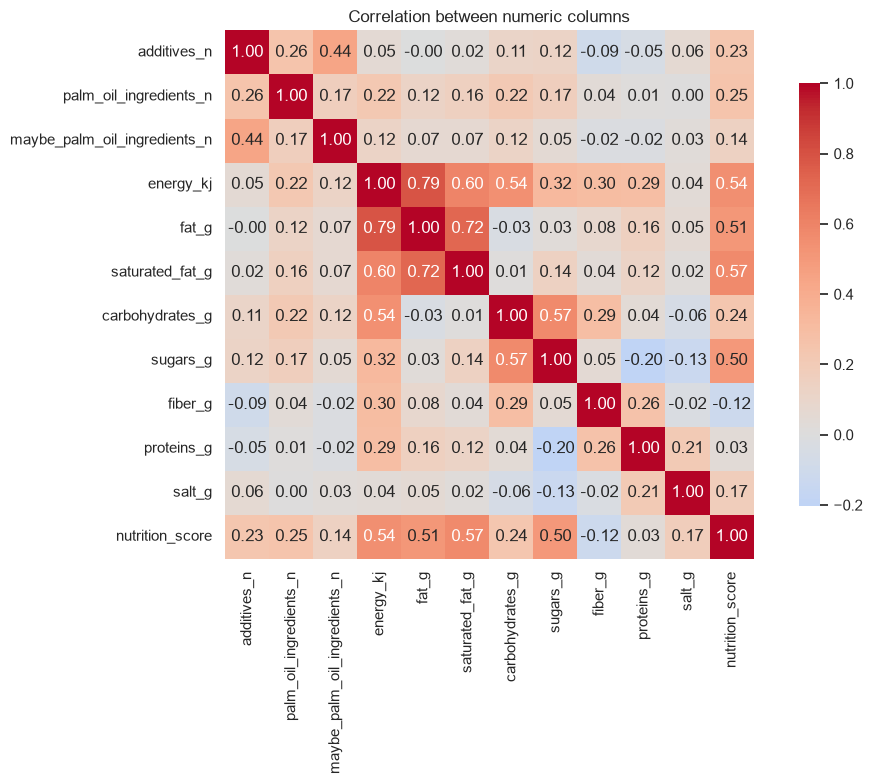

saturated_fat_g                 0.571
energy_kj                       0.545
fat_g                           0.511
sugars_g                        0.505
palm_oil_ingredients_n          0.248
carbohydrates_g                 0.238
additives_n                     0.235
salt_g                          0.174
maybe_palm_oil_ingredients_n    0.143
proteins_g                      0.032
fiber_g                        -0.122
Name: nutrition_score, dtype: float64

In [7]:
numeric_cols = df.select_dtypes("number").columns
corr = df[numeric_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation between numeric columns")
plt.tight_layout()
plt.show()

corr["nutrition_score"].drop("nutrition_score").sort_values(ascending=False).round(3)

**What it shows:** Saturated fat (0.57), energy (0.55), fat (0.51) and sugars (0.51) have the strongest positive correlation with the nutrition score. Fibre is the only negative one (-0.12), which makes sense because fibre earns "good" points in the Nutri-Score, and protein is close to zero. Some features are also strongly correlated with each other: energy and fat (0.79), fat and saturated fat (0.72).

**Decision:** I kept energy, fat and saturated fat even though they overlap, because each one is printed separately on a label and the tree models are not hurt by correlated inputs. I dropped `maybe_palm_oil_ingredients_n` because its correlation is weak (0.14) and it is only a guess. No single feature has a correlation above 0.6, so I expected a one-feature straight line to do badly and a model that uses all the features together to do much better.

### 3.2 Distribution of the target and key nutrients

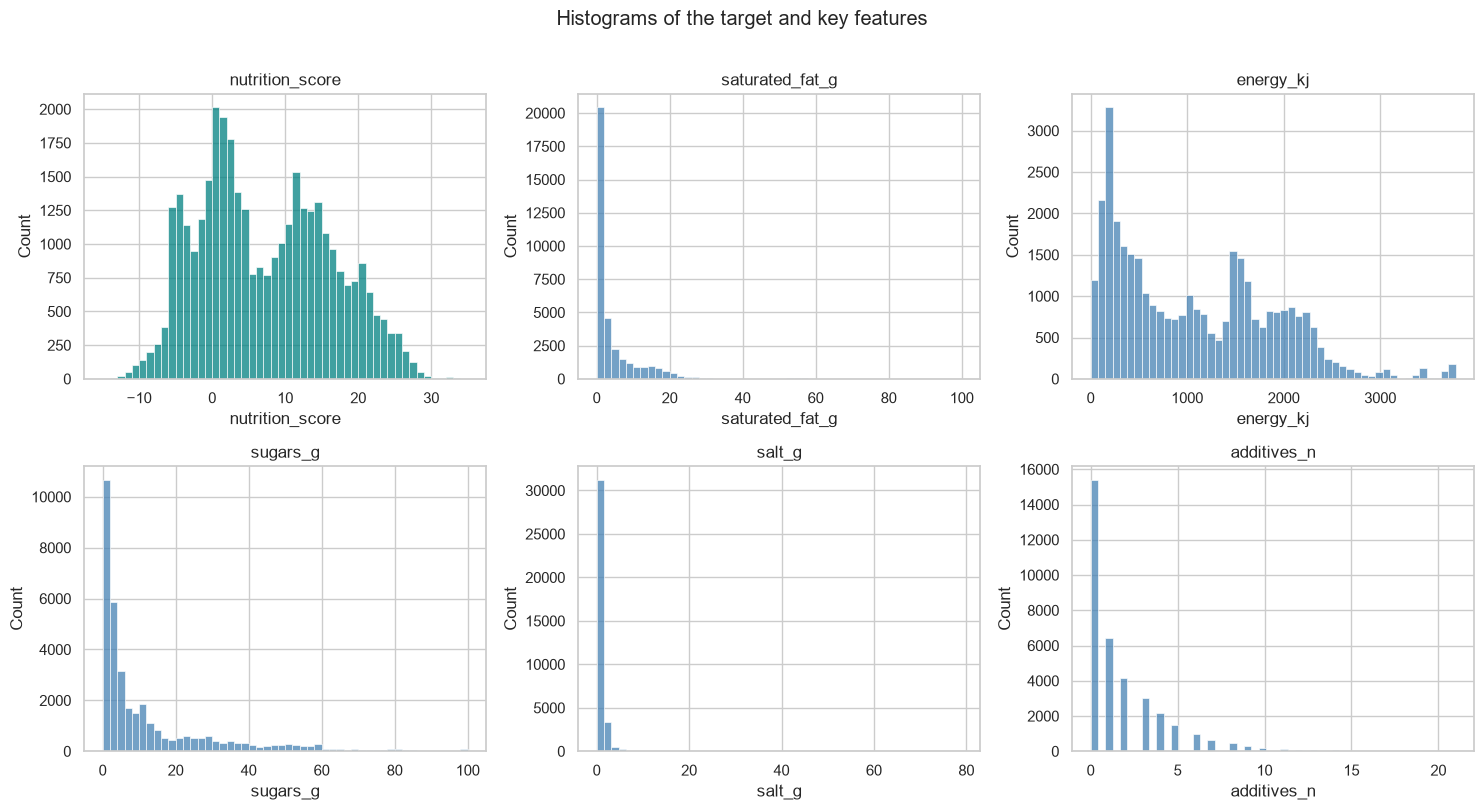

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
cols = ["nutrition_score", "saturated_fat_g", "energy_kj", "sugars_g", "salt_g", "additives_n"]
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(df[col], bins=50, ax=ax, color="teal" if col == "nutrition_score" else "steelblue")
    ax.set_title(col)
plt.suptitle("Histograms of the target and key features", y=1.01)
plt.tight_layout()
plt.show()

**What it shows:** The target covers its whole range (-15 to 35, median 6) and has two peaks: one around 0 (fruit, vegetables, cereals, plain foods) and one around 12 to 14 (snacks, sauces, sweet drinks). It is not strongly skewed, so I predict it directly with no transformation, and the two peaks are another sign that the food group matters. The nutrient columns are very right-skewed: most products have little saturated fat or salt, but a few (butter, oils, stock cubes) have very large values. Salt is the most extreme (skew of 17.5), and 43% of products have no additives at all.

**Decision:** The features are on very different scales (energy in hundreds or thousands of kJ, salt usually under 3 g), so I standardize them before training. This matters most for gradient descent, which takes uneven steps when features have different scales. I kept the extreme values because they are real products (pure oil really has 100 g of fat per 100 g), and the cleaning step already removed the impossible ones.

### 3.3 Nutrition score by food group

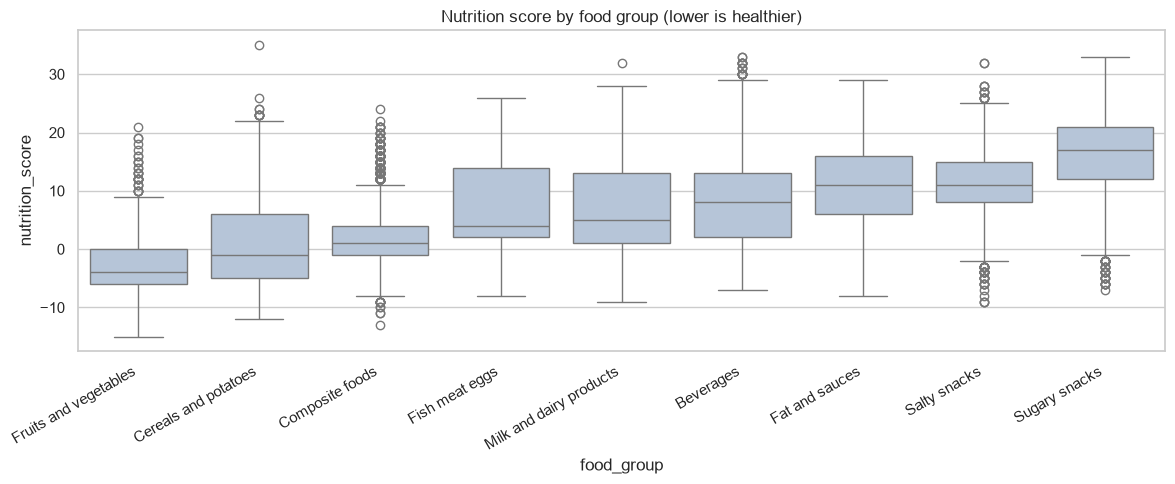

,count,mean
food_group,,
Fruits and vegetables,3578,-3.6
Cereals and potatoes,6218,0.8
Composite foods,4100,2.2
Milk and dairy products,3365,6.7
Fish meat eggs,2462,7.9
Beverages,4931,8.3
Fat and sauces,2642,11.1
Salty snacks,1810,11.5
Sugary snacks,6402,16.3


In [9]:
order = df.groupby("food_group")["nutrition_score"].median().sort_values().index
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="food_group", y="nutrition_score", order=order, color="lightsteelblue")
plt.xticks(rotation=30, ha="right")
plt.title("Nutrition score by food group (lower is healthier)")
plt.tight_layout()
plt.show()

df.groupby("food_group")["nutrition_score"].agg(["count", "mean"]).sort_values("mean").round(1)

**What it shows:** Food group changes the score a lot. Fruits and vegetables average -3.6, while sugary snacks average 16.3, almost 20 points apart. Beverages average 8.3 even though drinks are low in energy, because the Nutri-Score judges drinks with stricter thresholds than solid foods.

**Decision:** I kept `food_group` as a feature and one-hot encoded it. The fact that the same nutrient amount counts differently depending on the group also told me the relationship is not purely linear, so I expected the tree models to beat the linear ones.

## 4. Feature engineering

**Columns dropped and why**

| Column | Reason |
|---|---|
| `product_name` | Free text that identifies a product. It is unique for most rows and says nothing general about nutrition. |
| `countries` | Messy multi-value text (for example "France,Germany"). Where a product is sold does not change its nutrients, and Nigeria barely appears. |
| `food_subgroup` | 39 sub-categories nested inside `food_group`. It repeats the same information at a finer level, and many of its categories are tiny, which invites overfitting. |
| `maybe_palm_oil_ingredients_n` | Only an uncertain guess ("may be from palm oil") with weak correlation to the target. `palm_oil_ingredients_n` already carries the confirmed signal. |
| `nutrition_grade_fr`, `nutrition-score-uk_100g` (raw data) | Dropped during cleaning because they are other versions of the target (the A to E grade is cut directly from the score). Keeping them would leak the answer. |
| ~140 other raw columns | Mostly empty, or metadata such as URLs, dates and image links. |

**Features kept (11):** `food_group` (categorical) and `additives_n`, `palm_oil_ingredients_n`, `energy_kj`, `fat_g`, `saturated_fat_g`, `carbohydrates_g`, `sugars_g`, `fiber_g`, `proteins_g`, `salt_g` (numeric). These are all values a shopper can read from a label, which matters because they become the inputs of the mobile app.

**Features that matter most:** from the heatmap, saturated fat, energy, fat and sugars are the most linked to the score, and section 3.3 shows that food group matters a lot as well. The random forest importance chart in section 10 confirms which features the final model actually relies on.

In [10]:
TARGET = "nutrition_score"
CATEGORICAL = ["food_group"]
NUMERIC = ["additives_n", "palm_oil_ingredients_n", "energy_kj", "fat_g", "saturated_fat_g",
           "carbohydrates_g", "sugars_g", "fiber_g", "proteins_g", "salt_g"]
FEATURES = CATEGORICAL + NUMERIC

X = df[FEATURES]
y = df[TARGET]
print("X:", X.shape, " y:", y.shape)

X: (35508, 11)  y: (35508,)


### Converting the categorical column to numbers
`food_group` has 9 categories with no natural order, so it is one-hot encoded (one 0/1 column per group). Label encoding (0, 1, 2, ...) would wrongly tell the linear models that "Sugary snacks" is somehow bigger than "Beverages".

In [11]:
pd.get_dummies(X[CATEGORICAL]).astype(int).head()

,food_group_Beverages,food_group_Cereals and potatoes,food_group_Composite foods,food_group_Fat and sauces,food_group_Fish meat eggs,food_group_Fruits and vegetables,food_group_Milk and dairy products,food_group_Salty snacks,food_group_Sugary snacks
0,0,0,0,0,0,1,0,0,0
1,0,0,0,0,0,0,0,0,1
2,1,0,0,0,0,0,0,0,0
3,0,0,1,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,1


## 5. Train/test split and standardization

80% of the rows go to training and 20% to testing. The encoder and the scaler are fitted on the training set only, then applied to the test set, so no information about the test set leaks into training.

The one-hot encoder and `StandardScaler` are wrapped in a `ColumnTransformer`. Every model below uses the same fitted preprocessing, and it is saved together with the best model so the API can take raw label values.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
], sparse_threshold=0)

X_train_t = preprocessor.fit_transform(X_train)   # fit on train only
X_test_t = preprocessor.transform(X_test)

print("Train:", X_train_t.shape, " Test:", X_test_t.shape)
print("Mean of scaled train columns (should be ~0):", X_train_t[:, :len(NUMERIC)].mean(axis=0).round(3))

Train: (28406, 19)  Test: (7102, 19)
Mean of scaled train columns (should be ~0): [-0.  0. -0. -0. -0. -0.  0. -0. -0. -0.]


In [13]:
baseline_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print(f"Baseline (always predict the training mean): test MSE = {baseline_mse:.2f}, RMSE = {np.sqrt(baseline_mse):.2f}")

Baseline (always predict the training mean): test MSE = 79.85, RMSE = 8.94


## 6. Model 1: Linear regression with gradient descent (SGDRegressor)

### 6.1 Tuning
`SGDRegressor` is trained one epoch at a time with `partial_fit`, which lets me record the loss after every epoch. To keep the test set untouched while tuning, I split off 20% of the training set as a validation set and pick the settings with the lowest validation MSE.

Hyperparameters tried:
- **Learning rate** (`eta0`, constant schedule): 0.0001, 0.001, 0.01, 0.05
- **Regularization strength** (`alpha`, L2 penalty): 0.0001, 0.001, 0.01, 0.1
- **Number of epochs:** recorded at 5, 20, 50 and 100 epochs for every combination

In [14]:
def train_sgd(X_tr, y_tr, X_ev, y_ev, eta0, alpha, epochs, seed=RANDOM_STATE):
    # Train SGDRegressor for a number of epochs and keep the MSE after each one.
    model = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha, penalty="l2", random_state=seed)
    rng = np.random.default_rng(seed)
    y_tr = np.asarray(y_tr)
    train_hist, eval_hist = [], []
    for _ in range(epochs):
        idx = rng.permutation(len(y_tr))           # reshuffle every epoch
        model.partial_fit(X_tr[idx], y_tr[idx])
        train_hist.append(mean_squared_error(y_tr, model.predict(X_tr)))
        eval_hist.append(mean_squared_error(y_ev, model.predict(X_ev)))
    return model, train_hist, eval_hist


X_fit, X_val, y_fit, y_val = train_test_split(X_train_t, y_train, test_size=0.2, random_state=RANDOM_STATE)

EPOCH_CHECKS = [5, 20, 50, 100]
results = []
start = time.time()
for eta0 in [0.0001, 0.001, 0.01, 0.05]:
    for alpha in [0.0001, 0.001, 0.01, 0.1]:
        _, _, val_hist = train_sgd(X_fit, y_fit, X_val, y_val, eta0, alpha, max(EPOCH_CHECKS))
        row = {"eta0": eta0, "alpha": alpha}
        row.update({f"val_mse@{e}": val_hist[e - 1] for e in EPOCH_CHECKS})
        results.append(row)
print(f"Tuning took {time.time() - start:.0f}s")

tuning = pd.DataFrame(results)
tuning.round({c: 2 for c in tuning.columns if c.startswith("val")})

Tuning took 18s


,eta0,alpha,val_mse@5,val_mse@20,val_mse@50,val_mse@100
0,0.0001,0.0001,18.66,17.71,17.69,17.71
1,0.0001,0.0010,18.68,17.72,17.69,17.72
2,0.0001,0.0100,18.85,17.84,17.80,17.82
3,0.0001,0.1000,20.75,20.31,20.25,20.27
4,0.0010,0.0001,18.22,18.00,17.87,18.07
5,0.0010,0.0010,18.22,18.00,17.87,18.07
6,0.0010,0.0100,18.29,18.11,17.95,18.15
7,0.0010,0.1000,20.48,20.53,20.21,20.41
8,0.0100,0.0001,18.53,21.41,28.11,640.94
9,0.0100,0.0010,18.53,21.39,28.03,613.29


Best settings: eta0=0.0001, alpha=0.0001, epochs=50, validation MSE=17.69


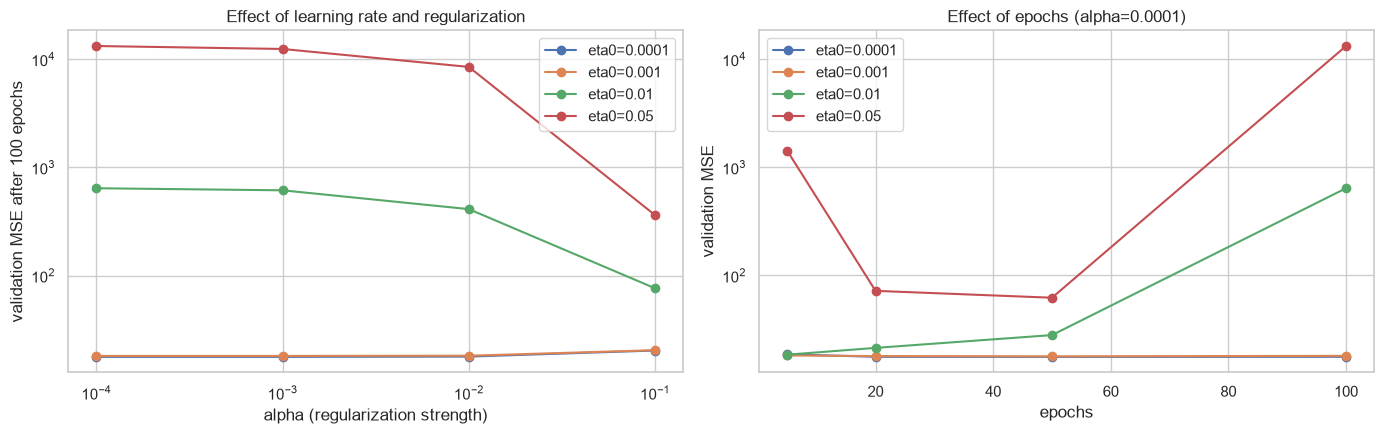

In [15]:
long = tuning.melt(id_vars=["eta0", "alpha"], var_name="epochs", value_name="val_mse")
long["epochs"] = long["epochs"].str.replace("val_mse@", "").astype(int)
best = long.loc[long["val_mse"].idxmin()]
BEST_ETA0, BEST_ALPHA, BEST_EPOCHS = best["eta0"], best["alpha"], int(best["epochs"])
print(f"Best settings: eta0={BEST_ETA0}, alpha={BEST_ALPHA}, epochs={BEST_EPOCHS}, validation MSE={best['val_mse']:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for eta0, grp in tuning.groupby("eta0"):
    axes[0].plot(grp["alpha"], grp["val_mse@100"], marker="o", label=f"eta0={eta0}")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("alpha (regularization strength)")
axes[0].set_ylabel("validation MSE after 100 epochs")
axes[0].set_title("Effect of learning rate and regularization")
axes[0].legend()

for eta0, grp in long[long["alpha"] == BEST_ALPHA].groupby("eta0"):
    axes[1].plot(grp["epochs"], grp["val_mse"], marker="o", label=f"eta0={eta0}")
axes[1].set_yscale("log")
axes[1].set_xlabel("epochs")
axes[1].set_ylabel("validation MSE")
axes[1].set_title(f"Effect of epochs (alpha={BEST_ALPHA})")
axes[1].legend()
plt.tight_layout()
plt.show()

**Tuning results:** 
- **Learning rate** had by far the biggest effect. With 0.0001 and 0.001 the model settled at a validation MSE of about 17.7 to 18. With 0.01 the loss got worse the longer it trained (28 after 50 epochs, over 600 after 100), and with 0.05 it exploded into the thousands. The steps were too big, so the model kept overshooting the minimum and diverged.
- **Regularization:** alpha from 0.0001 to 0.01 gave almost identical results. Alpha 0.1 raised the validation MSE to about 20.3 because the penalty shrinks the weights too much and the model underfits. The train and validation losses are already close, so the linear model is not overfitting and does not need extra regularization.
- **Epochs:** with the small learning rate most of the improvement happens in the first 20 epochs (18.66 at 5 epochs, 17.71 at 20). The best result was at 50 epochs (17.69), and going to 100 did not help. Extra epochs only made things worse when the learning rate was too high.

Best settings: **eta0 = 0.0001, alpha = 0.0001, 50 epochs**.

### 6.2 Loss curve
The final model uses the best settings and is trained on the full training set. Train and test MSE are stored after every epoch.

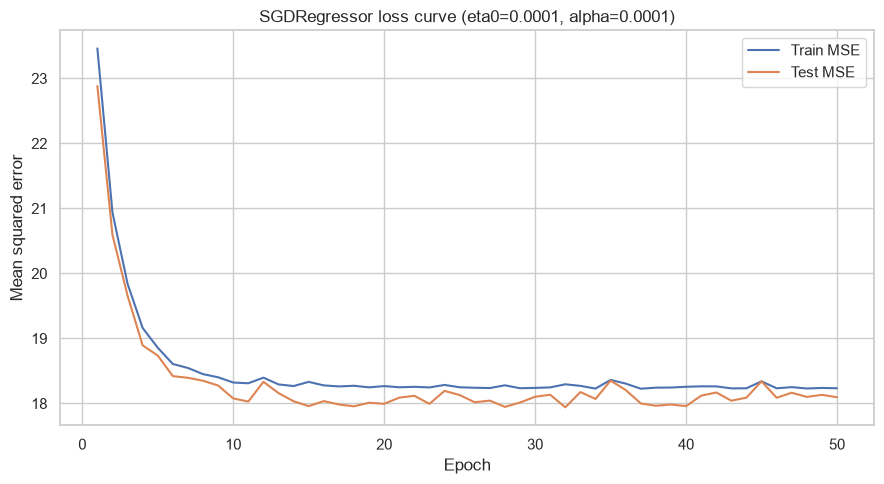

Test MSE after epochs 1-5: [22.88 20.59 19.66 18.89 18.74]
Final train MSE: 18.23   Final test MSE: 18.10


In [16]:
sgd, sgd_train_hist, sgd_test_hist = train_sgd(X_train_t, y_train, X_test_t, y_test,
                                               BEST_ETA0, BEST_ALPHA, BEST_EPOCHS)

epochs_axis = range(1, BEST_EPOCHS + 1)
plt.figure(figsize=(9, 5))
plt.plot(epochs_axis, sgd_train_hist, label="Train MSE")
plt.plot(epochs_axis, sgd_test_hist, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title(f"SGDRegressor loss curve (eta0={BEST_ETA0}, alpha={BEST_ALPHA})")
plt.legend()
plt.tight_layout()
plt.show()

print("Test MSE after epochs 1-5:", np.round(sgd_test_hist[:5], 2))
print(f"Final train MSE: {sgd_train_hist[-1]:.2f}   Final test MSE: {sgd_test_hist[-1]:.2f}")

**What it shows:** Both curves drop sharply in the first few epochs and then flatten at about 18. The test loss stays right next to the training loss (18.10 against 18.23), so the model is not overfitting. Its limit is the model type: a weighted sum of the features cannot copy the step-like rules of the Nutri-Score, where points jump at fixed amounts of sugar, saturated fat or salt.

## 7. Model 2: Linear regression, closed form 
Solves the least squares problem directly instead of taking gradient steps, so it is a good check on whether SGD found the best possible straight-line fit.

In [17]:
lin = LinearRegression()
lin.fit(X_train_t, y_train)
print(f"Train MSE: {mean_squared_error(y_train, lin.predict(X_train_t)):.2f}   "
      f"Test MSE: {mean_squared_error(y_test, lin.predict(X_test_t)):.2f}")

Train MSE: 18.21   Test MSE: 18.02


## 8. Model 3: Decision tree 
A single tree overfits if it grows without limit, so I compare a few maximum depths on the validation set first.

In [ ]:
for depth in [5, 10, 15, 20, None]:
    tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=2, random_state=RANDOM_STATE)
    tree.fit(X_fit, y_fit)
    print(f"max_depth={str(depth):>4}  train MSE={mean_squared_error(y_fit, tree.predict(X_fit)):6.2f}  "
          f"validation MSE={mean_squared_error(y_val, tree.predict(X_val)):6.2f}")

: 

In [19]:
TREE_DEPTH = 15
tree = DecisionTreeRegressor(max_depth=TREE_DEPTH, min_samples_leaf=2, random_state=RANDOM_STATE)
tree.fit(X_train_t, y_train)
print(f"Train MSE: {mean_squared_error(y_train, tree.predict(X_train_t)):.2f}   "
      f"Test MSE: {mean_squared_error(y_test, tree.predict(X_test_t)):.2f}")

Train MSE: 1.40   Test MSE: 4.38


Depth 15 gave the lowest validation MSE (4.47), so I used it. Shallower trees underfit (13.59 at depth 5). Deeper trees started to overfit: their training error kept falling (0.56 with no limit) while the validation error went back up (4.70). On the test set the tree reaches an MSE of 4.38, about four times lower than the linear models.

## 9. Model 4: Random forest 
An average of many trees, each trained on a random sample of rows and features. The number of trees and depth are kept moderate so the saved file stays small enough for GitHub and for the free Render server.

In [20]:
forest = RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=2,
                               n_jobs=-1, random_state=RANDOM_STATE)
start = time.time()
forest.fit(X_train_t, y_train)
print(f"Training took {time.time() - start:.1f}s")
print(f"Train MSE: {mean_squared_error(y_train, forest.predict(X_train_t)):.2f}   "
      f"Test MSE: {mean_squared_error(y_test, forest.predict(X_test_t)):.2f}")

Training took 4.0s


Train MSE: 0.77   Test MSE: 2.72


## 10. Comparing the four models
All four models are scored on the same test set.

In [21]:
models = {
    "SGDRegressor (gradient descent)": sgd,
    "LinearRegression (closed form)": lin,
    "DecisionTreeRegressor": tree,
    "RandomForestRegressor": forest,
}
rows = []
for name, model in models.items():
    train_pred, test_pred = model.predict(X_train_t), model.predict(X_test_t)
    rows.append({
        "model": name,
        "train_mse": mean_squared_error(y_train, train_pred),
        "test_mse": mean_squared_error(y_test, test_pred),
        "test_rmse": np.sqrt(mean_squared_error(y_test, test_pred)),
        "test_r2": r2_score(y_test, test_pred),
    })
comparison = pd.DataFrame(rows).sort_values("test_mse").reset_index(drop=True)
best_name = comparison.loc[0, "model"]
print(f"Baseline test MSE: {baseline_mse:.2f}")
print("Best model (lowest test MSE):", best_name)
comparison.round(3)

Baseline test MSE: 79.85
Best model (lowest test MSE): RandomForestRegressor


,model,train_mse,test_mse,test_rmse,test_r2
0,RandomForestRegressor,0.765,2.716,1.648,0.966
1,DecisionTreeRegressor,1.400,4.382,2.093,0.945
2,LinearRegression (closed form),18.213,18.016,4.245,0.774
3,SGDRegressor (gradient descent),18.233,18.095,4.254,0.773


**Best model:** the **random forest** has the lowest test MSE (2.72, which is an RMSE of 1.65 points and R2 of 0.966), so it is the model I saved. My criterion for the best model is the lowest MSE on the same test set, which none of the models saw during training.

How the dataset affected each model:
- **SGDRegressor and LinearRegression (about 18.0):** both reached almost the same error, which shows gradient descent found the same solution as the closed-form formula. They are limited because the Nutri-Score is built from threshold points (for example a fixed number of points for each band of sugar or salt) and different rules for drinks. A straight line cannot follow those steps, and the skewed nutrient columns make it worse.
- **DecisionTreeRegressor (4.38):** a tree splits on thresholds, which is exactly how the score is built, so it does much better. A single tree overfits, though (train 1.40 against test 4.38).
- **RandomForestRegressor (2.72):** averaging 100 trees smooths out the mistakes of single trees, so it has the lowest error on new products. Its training error (0.77) is lower than its test error, so there is some overfitting, but it still generalizes best.

All four models beat the baseline of always predicting the average (test MSE 79.85). The forest is usually less than 2 points off on a scale of about 50 points, and Nutri-Score grades (A to E) are 3 to 8 points wide, so a prediction rarely lands in the wrong grade. That makes it the right choice for an app that helps people compare products.

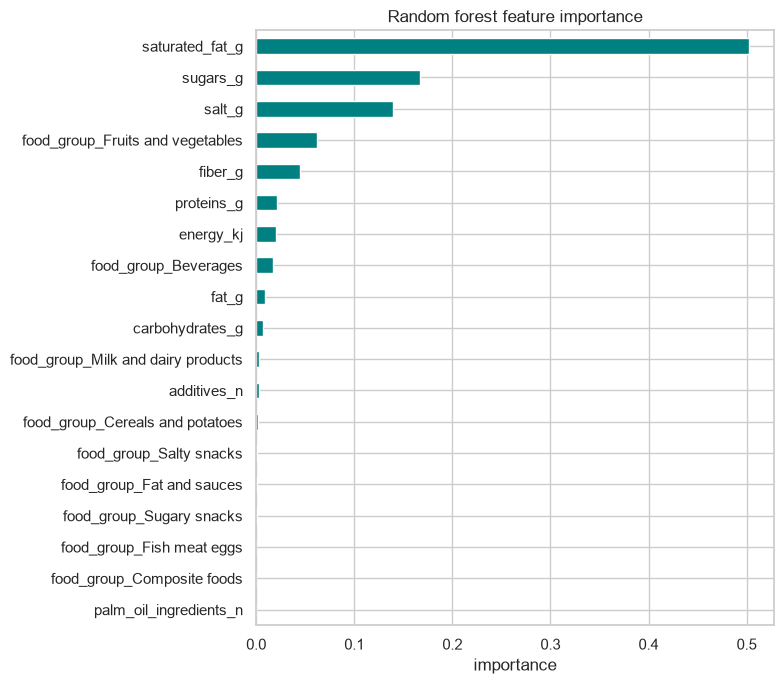

In [22]:
importances = pd.Series(forest.feature_importances_, index=preprocessor.get_feature_names_out())
importances.index = importances.index.str.replace("num__", "").str.replace("cat__", "")
importances.sort_values().plot.barh(figsize=(8, 7), color="teal")
plt.title("Random forest feature importance")
plt.xlabel("importance")
plt.tight_layout()
plt.show()

Saturated fat is by far the most important feature (0.50), followed by sugars (0.17) and salt (0.14). Salt only had a weak correlation in the heatmap (0.17) but matters a lot to the forest, which shows its effect is not linear: it only pushes the score up at higher amounts. Belonging to the fruit and vegetables group, and fibre, are next and push the score down. The number of additives and palm oil ingredients add almost nothing, because the Nutri-Score is calculated from nutrients and does not measure how processed a food is. For my mission that is worth knowing: an ultra-processed product can still get a fair score, so the app should show the additives count as a separate warning next to the predicted score.

## 11. Scatter plots: before and after fitting a line
The feature most correlated with the target is used. The line comes from a separate one-feature linear regression fitted only for this plot.

Most correlated feature: saturated_fat_g (r = 0.571)


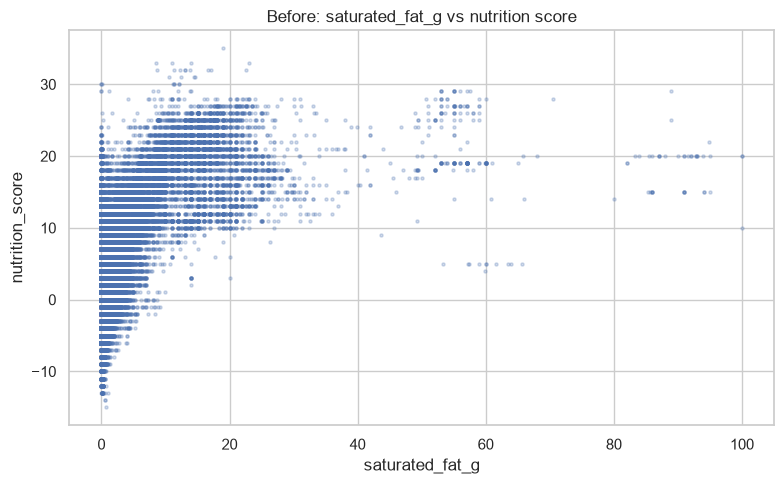

In [23]:
top_feature = corr["nutrition_score"].drop("nutrition_score").abs().idxmax()
print("Most correlated feature:", top_feature, f"(r = {corr.loc[top_feature, 'nutrition_score']:.3f})")

plt.figure(figsize=(8, 5))
plt.scatter(X_train[top_feature], y_train, s=5, alpha=0.25)
plt.xlabel(top_feature)
plt.ylabel("nutrition_score")
plt.title(f"Before: {top_feature} vs nutrition score")
plt.tight_layout()
plt.show()

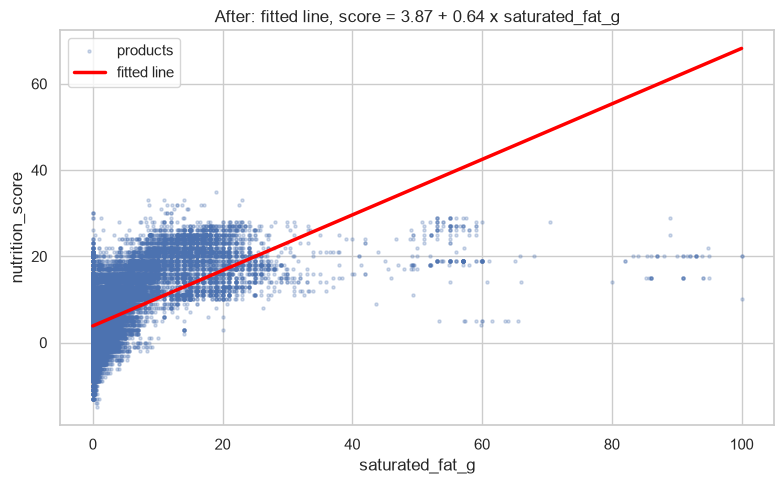

One-feature line test MSE: 53.22


In [24]:
one_feature = LinearRegression()
one_feature.fit(X_train[[top_feature]], y_train)
line_x = np.linspace(X_train[top_feature].min(), X_train[top_feature].max(), 100).reshape(-1, 1)
line_y = one_feature.predict(pd.DataFrame(line_x, columns=[top_feature]))

plt.figure(figsize=(8, 5))
plt.scatter(X_train[top_feature], y_train, s=5, alpha=0.25, label="products")
plt.plot(line_x, line_y, color="red", linewidth=2.5, label="fitted line")
plt.xlabel(top_feature)
plt.ylabel("nutrition_score")
plt.title(f"After: fitted line, score = {one_feature.intercept_:.2f} + {one_feature.coef_[0]:.2f} x {top_feature}")
plt.legend()
plt.tight_layout()
plt.show()

one_mse = mean_squared_error(y_test, one_feature.predict(X_test[[top_feature]]))
print(f"One-feature line test MSE: {one_mse:.2f}")

Saturated fat is the feature most correlated with the score (r = 0.57). The before plot shows a clear upward trend but a very wide spread: at 0 g of saturated fat, scores go from -13 to 30, because sugary drinks and sweets have no fat but still score badly. The fitted line on saturated fat alone has a test MSE of 53.2. It also keeps rising past the data, so for pure fats (around 60 to 100 g of saturated fat) it predicts scores of 40 to 68, which the Nutri-Score cannot even reach. The real scores level off at about 20 to 25. That is better than the baseline (79.9) but far worse than the linear model with all features (18.0) and the random forest (2.7), which is why this problem needs a multivariate model.

## 12. Saving the best model
The best model is saved together with its preprocessing (encoder and scaler) as one scikit-learn `Pipeline`, so the API can pass in raw label values and get a score back.

In [25]:
best_pipeline = Pipeline([("preprocess", preprocessor), ("model", models[best_name])])

# The saved pipeline must give the same test predictions as the model above.
check = mean_squared_error(y_test, best_pipeline.predict(X_test))
print(f"Pipeline test MSE: {check:.3f}")

joblib.dump(best_pipeline, MODEL_PATH, compress=3)
print(f"Saved {best_name} to {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")

Pipeline test MSE: 2.716


Saved RandomForestRegressor to ../API\best_model.pkl (15.5 MB)


## 13. Predicting one row of the test set
`predict_nutrition_score` loads the saved model from disk and predicts the score for a single product. The API uses the same function.

In [26]:
def predict_nutrition_score(features, model_path=MODEL_PATH):
    # Load the saved pipeline and predict the nutrition score for one product.
    # features is a dict (or one-row DataFrame) with the 11 input columns.
    model = joblib.load(model_path)
    row = pd.DataFrame([features]) if isinstance(features, dict) else features
    return float(model.predict(row[FEATURES])[0])


sample = X_test.iloc[[0]]
actual = y_test.iloc[0]
print("Product:", df.loc[sample.index[0], "product_name"])
display(sample)
predicted = predict_nutrition_score(sample.iloc[0].to_dict())
print(f"Predicted nutrition score: {predicted:.2f}")
print(f"Actual nutrition score:    {actual}")

Product: Courgettes en rondelles surgelés Bio


,food_group,additives_n,palm_oil_ingredients_n,energy_kj,fat_g,saturated_fat_g,carbohydrates_g,sugars_g,fiber_g,proteins_g,salt_g
19688,Fruits and vegetables,0,0,79.0,0.2,0.0,2.2,1.7,0.7,1.7,0.0


Predicted nutrition score: -5.56
Actual nutrition score:    -6


## 14. Summary

- The **random forest** is the best model, with a test MSE of 2.72 (RMSE 1.65 points) against 79.85 for the baseline, 18.0 for both linear models and 4.38 for the decision tree. It is saved with its preprocessing in `summative/API/best_model.pkl`.
- **Is the loss low enough?** For this use case, yes. An error of under 2 points on a scale of about 50 rarely changes a product's A to E grade, so a shopper comparing two products would get the right answer most of the time.
- **How to reduce it further:**
  - Add the fruit, vegetable and nut percentage. It is part of the official score but missing for almost every product in this dataset.
  - Train beverages separately, since the score uses different rules for drinks.
  - Collect Nigerian products, so that local foods are covered and not only European ones.
  - Tune the forest further (more trees, other depths), or try gradient boosting.
- **Limitations:** very few Nigerian products, and some crowdsourced labels are wrong. The score does not capture how processed a food is, so the additives count should be shown alongside the prediction. The app is for information, not medical advice.